# Modul 02 - Backpropagation dan Automatic Differentiation

**Nama:** Abdillah Fikri Alpome  
**NIM:** 123450062  
**Kelas:** RC  
**Tanggal eksekusi ulang:** 2026-10-27

Perbaikan salinan mahasiswa dalam repo berdasarkan materi Modul 02 versi 0.4.13
yang diberikan praktikan. Nilai Kasus 1 dan protokol XOR dipertahankan.
Hipotesis latihan ditulis untuk eksekusi ulang ini, bukan diklaim sebagai
catatan sebelum eksperimen historis.

Notebook dan hasil Modul 02 disimpan pada folder `notebooks/modul-02`.
Berkas pendukung berada di subfolder `hasil`. Jalankan **Restart Kernel and Run All**. Luaran utama:
`M02_123450062.ipynb`, `M02_123450062.pdf`, `M02_123450062_metrics.csv`;
catatan latihan terpisah: `latihan-02.md`.


**Adaptasi dan bantuan:** Kode mengadaptasi implementasi praktikum Fabio Banyu Cyto dengan izin pemilik melalui OpenAI Codex. Semua eksperimen pada berkas ini dijalankan ulang untuk NIM 123450062; hasil lama tidak dipakai sebagai hasil baru. Sumber: https://github.com/fabiobanyu/deep-learning-123450104 . Praktikan meninjau dan memahami hasil sebelum pengumpulan.


In [1]:
import json
import platform
import random
import time
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import Markdown, display

NAMA = 'Abdillah Fikri Alpome'
NIM = '123450062'
KELAS = 'RC'
assert NIM.isdigit() and len(NIM)>=4
SEED = int(NIM[-4:])  # Modul 02: 62; tidak ditambah 1000.
DEVICE = torch.device('cpu')
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
EPOCHS, LR = 400, 0.1
MODULE_DIR = Path('notebooks/modul-02')
OUTPUT_DIR = MODULE_DIR if MODULE_DIR.is_dir() else Path('.')
SUPPORT_DIR = OUTPUT_DIR/'hasil'
SUPPORT_DIR.mkdir(parents=True,exist_ok=True)
FIGURE_DIR = OUTPUT_DIR/'figures'
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
PREFIX = f'M02_{NIM}'
TEMPLATE_COLUMNS = 'run_id,module,student_id,seed,dataset,split,model,optimizer,learning_rate,batch_size,epochs,train_loss,val_loss,val_metric,test_metric,parameters,trainable_parameters,runtime_seconds,device,notes'.split(',')
METRICS_COLUMNS = TEMPLATE_COLUMNS+['record_type']  # Tambahan wajib checkpoint Modul 02, disetujui praktikan.
pd.set_option('display.precision',9)
pd.set_option('display.max_columns',25)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(SEED)
environment = {'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
    'torch':torch.__version__,'device':str(DEVICE),'dtype':str(torch.get_default_dtype()),
    'seed':SEED,'torch_threads':torch.get_num_threads()}
execution_date = datetime.now(ZoneInfo('Asia/Bangkok')).date().isoformat()
metrics_rows, gradient_tables, loop_results, loop_histories = [],{}, {}, {}
display(environment)


{'python': '3.14.7',
 'numpy': '2.5.3',
 'pandas': '3.0.5',
 'torch': '2.14.0+cpu',
 'device': 'cpu',
 'dtype': 'torch.float64',
 'seed': 62,
 'torch_threads': 1}

## A. Pre-lab

1. **Gradien lokal dan total:** gradien lokal adalah turunan keluaran suatu
   operasi terhadap masukannya; gradien total loss terhadap simpul menjumlahkan
   semua jalur dari simpul tersebut ke loss melalui chain rule.
2. **Backward dan skalar:** `backward()` tanpa argumen gradien hanya dapat
   membentuk seed gradien otomatis untuk keluaran skalar. Keluaran vektor juga
   dapat di-backward bila diberikan vektor `gradient` yang sesuai, atau direduksi
   terlebih dahulu dengan `sum()`/`mean()`.
3. **Akumulasi:** dua forward/backward pada parameter sama tanpa menghapus
   `.grad` menjumlahkan kontribusinya. Untuk backward pada graf yang sama,
   graf perlu dipertahankan; percobaan di sini memakai forward baru.
4. **BCE-logits:** $dL/dp=-y/p+(1-y)/(1-p)$ dan $dp/dz=p(1-p)$.
   Hasil kalinya $-y(1-p)+(1-y)p=p-y$. Bentuk $-y/p$ hanya salah satu
   bagian turunan terhadap probabilitas, bukan turunan terhadap logit.


## B. Turunan manual Kasus 1

Graf komputasi:

$$x \xrightarrow[\,W_1,b_1\,]{z_1=W_1x+b_1} z_1
 \xrightarrow{\mathrm{ReLU}} h
 \xrightarrow[\,W_2,b_2\,]{z_2=W_2h+b_2} z_2
 \xrightarrow{\sigma}p\xrightarrow{\mathrm{BCE}}L.$$

Gradien lokal simpul affine adalah $dz/dW=x$, $dz/db=1$, $dz/dx=W$;
ReLU memakai mask $1[z>0]$. Sigmoid dan BCE digabungkan menjadi $dL/dz_2=p-y$.

Dengan $x=[2,-1]$, $W_1=[[0.5,-0.5],[1,1]]$, $b_1=[0,0]$,
$W_2=[2,-1]$, $b_2=0.5$, $y=1$, diperoleh
$z_1=h=[1.5,1]$, $z_2=2.5$, $p=0.924141819979$, $L=0.078889734293$.

Tuliskan $d=p-y=-0.075858180021$:

$$dW_2=d\,h=[-0.113787270032,-0.075858180021],\quad db_2=d;$$
$$dh=d[2,-1]=[-0.151716360042,0.075858180021],\quad dz_1=dh\odot[1,1];$$
$$dW_1=\mathrm{outer}(dz_1,x)=
\begin{bmatrix}-0.303432720085&0.151716360042\\
0.151716360042&-0.075858180021\end{bmatrix},\quad db_1=dz_1.$$

| Parameter | Shape parameter dan gradien |
|---|---|
| W1 | (2,2) |
| b1 | (2,) |
| W2 | (2,) |
| b2 | skalar () |

Total 9 komponen. Bentuk outer product wajib mengikuti indeks neuron lalu
fitur; kebetulan matriks kasus ini simetris sehingga pertukaran urutan tidak
terdeteksi dari angkanya saja. Implementasi umum di bawah memakai batch
sebagai baris; satu contoh berarti batch berukuran 1.


Forward: {'z1': array([[1.5, 1. ]]), 'h': array([[1.5, 1. ]]), 'z2': array([2.5]), 'p': array([0.92414182]), 'loss': 0.07888973429254964}
W1 [[-0.30343272  0.15171636]
 [ 0.15171636 -0.07585818]] shape= (2, 2)
b1 [-0.15171636  0.07585818] shape= (2,)
W2 [-0.11378727 -0.07585818] shape= (2,)
b2 -0.07585818002124345 shape= ()


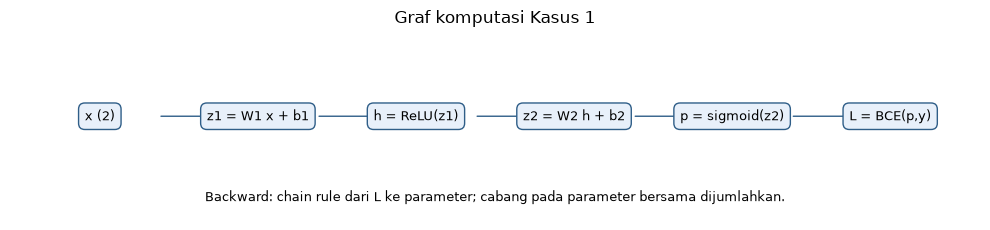

In [2]:
PARAMS = {'W1':np.array([[0.5,-0.5],[1.,1.]],dtype=np.float64),
          'b1':np.array([0.,0.],dtype=np.float64),
          'W2':np.array([2.,-1.],dtype=np.float64),'b2':np.array(0.5,dtype=np.float64)}
X1 = np.array([[2.,-1.]],dtype=np.float64)
Y1 = np.array([1.],dtype=np.float64)

def clone_params(params):
    return {name:value.copy() for name,value in params.items()}

def sigmoid_stabil(z):
    z = np.asarray(z,dtype=np.float64)
    out = np.empty_like(z)
    positive = z>=0
    out[positive] = 1/(1+np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    out[~positive] = exp_z/(1+exp_z)
    return out

def forward_np(X,y,params,activation='relu'):
    assert X.ndim==2 and y.shape==(len(X),)
    z1 = X@params['W1'].T+params['b1']
    h = np.maximum(z1,0) if activation=='relu' else np.tanh(z1)
    z2 = h@params['W2']+params['b2']
    p = sigmoid_stabil(z2)
    losses = np.logaddexp(0.,z2)-y*z2
    return {'X':X,'y':y,'z1':z1,'h':h,'z2':z2,'p':p,
            'individual_losses':losses,'loss':float(losses.mean()),'activation':activation}

def backward_np(cache,params):
    # Chain rule diturunkan manual; fungsi ini tidak memakai autograd.
    dz2 = (cache['p']-cache['y'])/len(cache['y'])
    dW2 = cache['h'].T@dz2
    db2 = np.array(dz2.sum())
    dh = dz2[:,None]*params['W2'][None,:]
    local = (cache['z1']>0) if cache['activation']=='relu' else 1-cache['h']**2
    dz1 = dh*local
    grads = {'W1':dz1.T@cache['X'],'b1':dz1.sum(axis=0),'W2':dW2,'b2':db2}
    assert all(grads[n].shape==params[n].shape for n in params)
    return grads,{'dz2':dz2,'dh':dh,'dz1':dz1}

base_cache = forward_np(X1,Y1,PARAMS)
base_grad,base_intermediate = backward_np(base_cache,PARAMS)
assert np.allclose(base_cache['z1'],[[1.5,1.]])
assert np.allclose(base_cache['z2'],[2.5])
assert np.isclose(base_cache['loss'],0.0788897342925496,atol=1e-12)
assert np.allclose(base_grad['W2'],[-0.113787270032,-0.075858180021],atol=1e-12)
print('Forward:',{n:base_cache[n] for n in ['z1','h','z2','p','loss']})
for name,value in base_grad.items():
    print(name,value,'shape=',value.shape)

fig,ax = plt.subplots(figsize=(10,2.4))
labels = ['x (2)','z1 = W1 x + b1','h = ReLU(z1)','z2 = W2 h + b2','p = sigmoid(z2)','L = BCE(p,y)']
for j,label in enumerate(labels):
    xx = 0.06+j*0.176
    ax.text(xx,0.55,label,ha='center',va='center',fontsize=9,
            bbox={'boxstyle':'round,pad=0.5','facecolor':'#e8f0fa','edgecolor':'#2f5e88'})
    if j<5:
        ax.annotate('',xy=(xx+0.14,0.55),xytext=(xx+0.065,0.55),
                    arrowprops={'arrowstyle':'->','color':'#2f5e88'})
ax.text(0.5,0.1,'Backward: chain rule dari L ke parameter; cabang pada parameter bersama dijumlahkan.',
        ha='center',fontsize=9)
ax.set(title='Graf komputasi Kasus 1',xlim=(-0.04,1.04),ylim=(0,1))
ax.axis('off')
fig.tight_layout()
plt.show()


## C. Autograd dan akumulasi

Setiap parameter dibuat sebagai tensor daun float64 dengan
`requires_grad=True`. Loss menerima logit mentah. Hasil autograd harus cocok
dengan fungsi chain rule NumPy, dengan selisih absolut < $10^{-10}$.


In [3]:
def torch_case(X,y,params,activation='relu'):
    tensors = {n:torch.tensor(v,dtype=torch.float64,device=DEVICE,requires_grad=True)
               for n,v in params.items()}
    tx,ty = torch.tensor(X,device=DEVICE),torch.tensor(y,device=DEVICE)
    z1 = tx@tensors['W1'].T+tensors['b1']
    h = torch.relu(z1) if activation=='relu' else torch.tanh(z1)
    z2 = h@tensors['W2']+tensors['b2']
    loss = nn.BCEWithLogitsLoss()(z2,ty)
    assert all(t.is_leaf and t.requires_grad for t in tensors.values())
    return tensors,loss

def autograd_np(X,y,params,activation='relu'):
    tensors,loss = torch_case(X,y,params,activation)
    loss.backward()
    return {n:t.grad.detach().cpu().numpy().copy() for n,t in tensors.items()}

base_auto = autograd_np(X1,Y1,PARAMS)
for name in PARAMS:
    error = float(np.max(np.abs(base_grad[name]-base_auto[name])))
    print(name,'selisih absolut maksimum:',error)
    assert error<1e-10

tensors,_ = torch_case(X1,Y1,PARAMS)
def fresh_loss():
    z1 = torch.tensor(X1,device=DEVICE)@tensors['W1'].T+tensors['b1']
    logits = torch.relu(z1)@tensors['W2']+tensors['b2']
    return nn.BCEWithLogitsLoss()(logits,torch.tensor(Y1,device=DEVICE))

fresh_loss().backward()
grad_once = tensors['W2'].grad.detach().clone()
fresh_loss().backward()
grad_twice = tensors['W2'].grad.detach().clone()
assert torch.allclose(grad_twice,2*grad_once)
for tensor in tensors.values():
    tensor.grad = None
fresh_loss().backward()
grad_reset = tensors['W2'].grad.detach().clone()
assert torch.allclose(grad_reset,grad_once)
display(pd.DataFrame({'satu_backward':grad_once.cpu().numpy(),
    'dua_backward_tanpa_reset':grad_twice.cpu().numpy(),'sesudah_reset':grad_reset.cpu().numpy()}))


W1 selisih absolut maksimum: 0.0
b1 selisih absolut maksimum: 0.0
W2 selisih absolut maksimum: 0.0
b2 selisih absolut maksimum: 0.0


,satu_backward,dua_backward_tanpa_reset,sesudah_reset
0,-0.11378727,-0.22757454,-0.11378727
1,-0.07585818,-0.15171636,-0.07585818


## D. Gradient checking dan pencatatan

$$g_{\mathrm{num}}=\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon},
\qquad r=\frac{|g_{\mathrm{manual}}-g_{\mathrm{num}}|}
{|g_{\mathrm{manual}}|+|g_{\mathrm{num}}|+10^{-12}}.$$

Setiap komponen diperiksa, bukan sekadar norma gabungan. Parameter selalu
disalin sebelum perturbasi. Toleransi utama $r<10^{-5}$ pada float64 dengan
$\epsilon=10^{-5}$. Nilai gradien nol dilaporkan juga; relative error dapat
tepat nol bila kedua metode menghasilkan nol.

CSV utama mempertahankan **20 kolom template resmi dalam urutan semula**,
ditambah `record_type` pada kolom terakhir sesuai pemeriksa resmi Modul 02
dan persetujuan praktikan. Nilainya `gradient_check` atau `training_loop`.
Untuk baris gradient
check, `notes` memuat JSON berisi parameter, indeks, manual, autograd, numerik,
relative error, dan epsilon; `train_loss` memuat loss kasus tetap.
Untuk baris diagnosis, `notes` memuat tahap, loss awal/akhir, objective,
accuracy XOR, dan norma parameter. Kolom validation/test dikosongkan karena
modul ini tidak memakai split tersebut. Tabel rinci juga diekspor sebagai
CSV pendamping agar mudah dibaca, tanpa mengganti skema metrics utama.


In [4]:
def export_metrics():
    table = pd.DataFrame(metrics_rows,columns=METRICS_COLUMNS)
    assert list(table.columns)==METRICS_COLUMNS
    table.to_csv(OUTPUT_DIR/f'{PREFIX}_metrics.csv',index=False)
    return table

def metric_row(run_id,model,dataset,split,parameters,batch_size,epochs,train_loss,runtime,notes,optimizer='none',lr=None):
    row = dict.fromkeys(METRICS_COLUMNS,None)
    original_type = notes['record_type']
    record_type = 'gradient_check' if original_type=='gradient_check' else 'training_loop'
    notes = dict(notes,record_type=record_type,run_role=original_type)
    row.update(run_id=run_id,module='M02',student_id=NIM,seed=SEED,dataset=dataset,
        split=split,model=model,optimizer=optimizer,learning_rate=lr,
        batch_size=batch_size,epochs=epochs,train_loss=train_loss,
        parameters=parameters,trainable_parameters=parameters,
        runtime_seconds=runtime,device=str(DEVICE),record_type=record_type,
        notes=json.dumps(notes,ensure_ascii=False,separators=(',',':')))
    return row

def finite_difference(X,y,params,activation,name,index,eps):
    plus,minus = clone_params(params),clone_params(params)
    plus[name][index] += eps
    minus[name][index] -= eps
    return (forward_np(X,y,plus,activation)['loss']-forward_np(X,y,minus,activation)['loss'])/(2*eps)

def gradient_check(case_id,X,y,params,activation='relu',eps=1e-5,require_pass=True):
    original = clone_params(params)
    cache = forward_np(X,y,params,activation)
    manual,_ = backward_np(cache,params)
    auto = autograd_np(X,y,params,activation)
    table_rows = []
    for name in ['W1','b1','W2','b2']:
        for index in np.ndindex(params[name].shape):
            start = time.perf_counter()
            gmanual,gauto = float(manual[name][index]),float(auto[name][index])
            gnum = float(finite_difference(X,y,params,activation,name,index,eps))
            rel = abs(gmanual-gnum)/(abs(gmanual)+abs(gnum)+1e-12)
            elapsed = time.perf_counter()-start
            assert abs(gmanual-gauto)<1e-10
            record = {'case':case_id,'parameter':name,'index':str(index),'manual':gmanual,
                      'autograd':gauto,'numerik':gnum,'rel_err':rel,'epsilon':eps}
            table_rows.append(record)
            suffix = '_'.join(map(str,index)) if index else 'scalar'
            notes = dict(record,record_type='gradient_check',stage=case_id,
                         loss_awal=cache['loss'],loss_akhir=cache['loss'],status='ok')
            metrics_rows.append(metric_row(f'{case_id}_{name}_{suffix}',
                f'FNN(2-{len(params["b1"])}-1;{activation})','fixed-example',
                'fixed-example' if len(X)==1 else 'fixed-batch',
                sum(p.size for p in params.values()),len(X),0,cache['loss'],elapsed,notes))
    assert all(np.array_equal(original[n],params[n]) for n in params)
    table = pd.DataFrame(table_rows)
    assert len(table)==sum(p.size for p in params.values())
    if require_pass:
        assert table.rel_err.max()<1e-5
    gradient_tables[case_id] = table
    export_metrics()
    display(table)
    print(case_id,'maksimum relative error:',table.rel_err.max())
    return table

tabel_kasus1 = gradient_check('gradcheck_kasus1',X1,Y1,PARAMS)
assert len(tabel_kasus1)==9


,case,parameter,index,manual,autograd,numerik,rel_err,epsilon
0,gradcheck_kasus1,W1,"(0, 0)",-0.30343272,-0.30343272,-0.30343272,1.073134012e-10,0.00001
1,gradcheck_kasus1,W1,"(0, 1)",0.15171636,0.15171636,0.15171636,3.413585960e-11,0.00001
2,gradcheck_kasus1,W1,"(1, 0)",0.15171636,0.15171636,0.15171636,3.413585960e-11,0.00001
3,gradcheck_kasus1,W1,"(1, 1)",-0.07585818,-0.07585818,-0.07585818,1.122192236e-10,0.00001
4,gradcheck_kasus1,b1,"(0,)",-0.15171636,-0.15171636,-0.15171636,3.413585960e-11,0.00001
5,gradcheck_kasus1,b1,"(1,)",0.07585818,0.07585818,0.07585818,1.122192236e-10,0.00001
6,gradcheck_kasus1,W2,"(0,)",-0.11378727,-0.11378727,-0.11378727,8.292082633e-11,0.00001
7,gradcheck_kasus1,W2,"(1,)",-0.07585818,-0.07585818,-0.07585818,1.122192236e-10,0.00001
8,gradcheck_kasus1,b2,(),-0.07585818,-0.07585818,-0.07585818,1.122192236e-10,0.00001


gradcheck_kasus1 maksimum relative error: 1.1221922358447185e-10


### Checkpoint komputasional

Sembilan komponen Kasus 1 diperiksa terhadap autograd dan finite difference.
Assertion bukan pengganti verifikasi asisten pengampu. Lanjut ke Bagian E
setelah seluruh baris utama berada di bawah toleransi.

## E. Diagnosis empat kesalahan loop

| Tahap | Baris bermasalah | Perbaikan kumulatif | Gejala yang diperiksa |
|---|---|---|---|
| rusak | Dua Linear tanpa aktivasi | Belum diperbaiki | Fungsi tetap affine; XOR tidak terpisah linear |
| perbaikan-1 | Tidak ada ReLU | Tambahkan ReLU | Nonlinearitas tersedia |
| perbaikan-2 | BCEWithLogitsLoss(sigmoid(logits), y) | Gunakan logit mentah | Objective dibandingkan BCE yang benar |
| perbaikan-3 | step sebelum backward | backward lalu step | Jumlah update dan state epoch 399 dibandingkan |
| perbaikan-4 | zero_grad tidak dipanggil | Hapus gradien tiap epoch | Norma parameter/gradien dan loss diperiksa |

Seperti revisi 2026.2, cabang urutan salah membangun ulang graf setelah
`step()`. Ini mempertahankan empat cacat konseptual tetapi menghindari
in-place version mismatch pada PyTorch 2.x. Objective yang dicatat tetap
objective **sebelum update**; BCE benar dievaluasi terpisah pada logit.
Semua tahap di-reset ke seed yang sama dan memakai 4 hidden units,
SGD 0.1, 400 epoch, satu batch empat titik XOR.


In [5]:
X_xor = torch.tensor([[0.,0.],[0.,1.],[1.,0.],[1.,1.]],device=DEVICE)
y_xor = torch.tensor([[0.],[1.],[1.],[0.]],device=DEVICE)

def parameter_norm(model):
    return float(torch.sqrt(sum((p.detach()**2).sum() for p in model.parameters())).item())

@torch.no_grad()
def evaluate_xor(model):
    logits = model(X_xor)
    loss = nn.BCEWithLogitsLoss()(logits,y_xor).item()
    predictions = (logits>=0).to(torch.int64)
    correct = int((predictions==y_xor.to(torch.int64)).sum().item())
    return {'loss':loss,'correct':correct,'accuracy':correct/4,
            'predictions':predictions.cpu().flatten().tolist(),
            'max_abs_logit':float(logits.abs().max().item()),'parameter_norm':parameter_norm(model)}

def build_xor(use_relu=True):
    seed_everything(SEED)
    layers = [nn.Linear(2,4)]
    if use_relu:
        layers.append(nn.ReLU())
    layers.append(nn.Linear(4,1))
    model = nn.Sequential(*layers).to(DEVICE)
    assert sum(p.numel() for p in model.parameters())==17
    return model

def train_varian(run_id,use_relu,raw_logits,correct_order,clear_grad):
    model = build_xor(use_relu)
    optimizer = torch.optim.SGD(model.parameters(),lr=LR)
    criterion = nn.BCEWithLogitsLoss()
    initial = evaluate_xor(model)
    history,penultimate_state = [],None
    updates = 0
    start = time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        if clear_grad:
            optimizer.zero_grad()
        logits = model(X_xor)
        objective = criterion(logits if raw_logits else torch.sigmoid(logits),y_xor)
        objective_value = float(objective.item())
        if correct_order:
            objective.backward()
            optimizer.step()
            updates += 1
        else:
            # Revisi resmi 2026.2: graf baru setelah step untuk menghindari galat in-place.
            has_gradient = any(p.grad is not None for p in model.parameters())
            optimizer.step()
            updates += int(has_gradient)
            fresh_logits = model(X_xor)
            fresh_objective = criterion(fresh_logits if raw_logits else torch.sigmoid(fresh_logits),y_xor)
            fresh_objective.backward()
        state = evaluate_xor(model)
        grad_norm = float(torch.sqrt(sum((p.grad.detach()**2).sum() for p in model.parameters()
                                        if p.grad is not None)).item())
        history.append({'epoch':epoch,'objective_pre':objective_value,'true_loss_post':state['loss'],
                        'parameter_norm':state['parameter_norm'],'gradient_norm':grad_norm,'correct':state['correct']})
        if epoch==EPOCHS-1:
            penultimate_state = {n:p.detach().clone() for n,p in model.named_parameters()}
    elapsed = time.perf_counter()-start
    final = evaluate_xor(model)
    record = {'run_id':run_id,'loss_awal':initial['loss'],'loss_akhir':final['loss'],
        'objective_awal':history[0]['objective_pre'],'objective_akhir':history[-1]['objective_pre'],
        'benar_dari_4':final['correct'],'accuracy':final['accuracy'],'norma_parameter':final['parameter_norm'],
        'max_abs_logit':final['max_abs_logit'],'prediksi':final['predictions'],
        'epochs':EPOCHS,'updates':updates,'runtime_seconds':elapsed,
        'use_relu':use_relu,'raw_logits':raw_logits,'correct_order':correct_order,'clear_grad':clear_grad}
    loop_results[run_id] = record
    loop_histories[run_id] = pd.DataFrame(history)
    metrics_rows.append(metric_row(run_id,'FNN(2-4-1;relu)' if use_relu else 'FNN(2-4-1;affine)',
        'XOR','train-only',17,4,EPOCHS,final['loss'],elapsed,
        dict(record,record_type='loop_diagnosis',stage=run_id,status='ok'),'SGD',LR))
    export_metrics()
    return model,record,penultimate_state

def train_rusak():
    return train_varian('loop_rusak',False,False,False,False)

model_rusak,rusak,_ = train_rusak()
print('Objective yang dilihat loop rusak:',rusak['objective_awal'],'->',rusak['objective_akhir'])
print('BCE benar atas logit:',rusak['loss_awal'],'->',rusak['loss_akhir'])
print('Prediksi:',rusak['prediksi'],'target:',y_xor.int().flatten().tolist())


Objective yang dilihat loop rusak: 0.732822384960949 -> 0.5981758072995147
BCE benar atas logit: 0.705380294912693 -> 297.93672101572736
Prediksi: [0, 1, 0, 0] target: [0, 1, 1, 0]


,run_id,loss_awal,loss_akhir,objective_akhir,benar_dari_4,norma_parameter,updates
0,loop_rusak,0.705380295,297.936721016,0.598175807,3,56.833352425,399
1,loop_perbaikan_1,0.688005322,0.000000028,0.503204449,4,68.303048270,399
2,loop_perbaikan_2,0.688005322,0.000000000,0.000000000,4,140.912434039,399
3,loop_perbaikan_3,0.688005322,0.000000000,0.000000000,4,141.285372587,400
4,loop_perbaikan_4,0.688005322,0.126863538,0.126920507,4,5.191053668,400


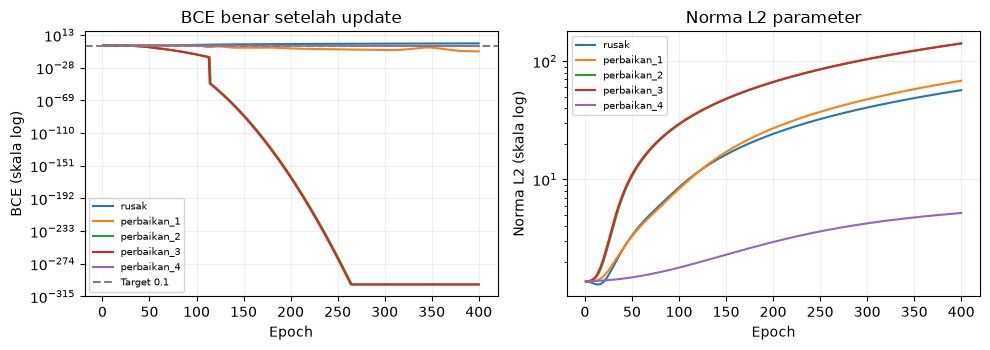

In [6]:
stage_models = {'loop_rusak':model_rusak}
stage_flags = [
    ('loop_perbaikan_1',True,False,False,False),
    ('loop_perbaikan_2',True,True,False,False),
    ('loop_perbaikan_3',True,True,True,False),
    ('loop_perbaikan_4',True,True,True,True),
]
stage3_epoch399 = None
for run_id,*flags in stage_flags:
    model,record,penultimate = train_varian(run_id,*flags)
    stage_models[run_id] = model
    if run_id=='loop_perbaikan_3':
        stage3_epoch399 = penultimate

# Dengan graf dibangun ulang, urutan salah tertinggal tepat satu update.
assert loop_results['loop_perbaikan_2']['updates']==399
assert loop_results['loop_perbaikan_3']['updates']==400
assert all(torch.equal(p,stage3_epoch399[n])
           for n,p in stage_models['loop_perbaikan_2'].named_parameters())
stages = ['loop_rusak']+[f'loop_perbaikan_{i}' for i in range(1,5)]
tabel_loop = pd.DataFrame([loop_results[r] for r in stages])
display(tabel_loop[['run_id','loss_awal','loss_akhir','objective_akhir','benar_dari_4','norma_parameter','updates']])
fig,axes = plt.subplots(1,2,figsize=(10,3.6))
for run_id in stages:
    h = loop_histories[run_id]
    axes[0].semilogy(h.epoch,np.maximum(h.true_loss_post,1e-300),label=run_id.replace('loop_',''))
    axes[1].semilogy(h.epoch,np.maximum(h.parameter_norm,1e-300),label=run_id.replace('loop_',''))
axes[0].set(title='BCE benar setelah update',xlabel='Epoch',ylabel='BCE (skala log)')
axes[0].axhline(0.1,color='gray',ls='--',label='Target 0.1')
axes[1].set(title='Norma L2 parameter',xlabel='Epoch',ylabel='Norma L2 (skala log)')
for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


In [7]:
def train_benar():
    # Implementasi bersih, terpisah dari empat saklar diagnosis.
    model = build_xor(True)
    optimizer = torch.optim.SGD(model.parameters(),lr=LR)
    criterion = nn.BCEWithLogitsLoss()
    initial = evaluate_xor(model)
    history = []
    start = time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        optimizer.zero_grad()
        logits = model(X_xor)
        loss = criterion(logits,y_xor)
        loss_value = float(loss.item())
        loss.backward()
        optimizer.step()
        state = evaluate_xor(model)
        grad_norm = float(torch.sqrt(sum((p.grad.detach()**2).sum() for p in model.parameters())).item())
        history.append({'epoch':epoch,'objective_pre':loss_value,'true_loss_post':state['loss'],
            'parameter_norm':state['parameter_norm'],'gradient_norm':grad_norm,'correct':state['correct']})
    elapsed = time.perf_counter()-start
    final = evaluate_xor(model)
    record = {'run_id':'loop_benar_verifikasi','loss_awal':initial['loss'],'loss_akhir':final['loss'],
        'objective_awal':history[0]['objective_pre'],'objective_akhir':history[-1]['objective_pre'],
        'benar_dari_4':final['correct'],'accuracy':final['accuracy'],'norma_parameter':final['parameter_norm'],
        'max_abs_logit':final['max_abs_logit'],'prediksi':final['predictions'],'epochs':EPOCHS,
        'updates':EPOCHS,'runtime_seconds':elapsed}
    loop_results[record['run_id']] = record
    loop_histories[record['run_id']] = pd.DataFrame(history)
    metrics_rows.append(metric_row(record['run_id'],'FNN(2-4-1;relu)','XOR','train-only',17,4,
        EPOCHS,final['loss'],elapsed,dict(record,record_type='loop_verification',stage='clean_loop',status='ok'),'SGD',LR))
    export_metrics()
    return model,record

model_benar,benar = train_benar()
assert np.array_equal(loop_histories['loop_benar_verifikasi'].objective_pre,
                      loop_histories['loop_perbaikan_4'].objective_pre)
assert all(torch.equal(p,q) for p,q in zip(model_benar.parameters(),
                                         stage_models['loop_perbaikan_4'].parameters()))
target_reached = benar['loss_akhir']<0.1 and benar['benar_dari_4']==4
print('Loop benar identik dengan perbaikan-4.')
print('Loss akhir sesudah update:',benar['loss_akhir'],'prediksi:',benar['prediksi'])
print('Target loss < 0.1 dan 4/4 benar:', 'tercapai' if target_reached else 'belum tercapai')
print('Tidak mengubah seed, hidden size, learning rate, atau epoch untuk memaksakan target.')


Loop benar identik dengan perbaikan-4.
Loss akhir sesudah update: 0.1268635379296944 prediksi: [0, 1, 1, 0]
Target loss < 0.1 dan 4/4 benar: belum tercapai
Tidak mengubah seed, hidden size, learning rate, atau epoch untuk memaksakan target.


## F. Latihan mandiri: tanh

**Prediksi kerja sebelum eksekusi ulang:** norma Frobenius gradien $W_1$
diperkirakan mengecil. Pada $z_1=[1.5,1]$, turunan tanh berada di bawah 1,
sedangkan kedua turunan ReLU bernilai 1. Tetapi $p-y$ juga berubah sehingga
kesimpulan ini perlu diperiksa dari angka, bukan hanya dari turunan aktivasi.

Turunan ulang tanpa autograd:

$$h_t=[\tanh(1.5),\tanh(1)],\quad z_{2t}=2h_{t1}-h_{t2}+0.5,\quad d_t=\sigma(z_{2t})-1;$$
$$\frac{\partial L}{\partial z_1}
=d_t[2,-1]\odot[1-\tanh^2(1.5),1-\tanh^2(1)];$$
$$dW_1=\mathrm{outer}(dz_1,[2,-1]),\quad db_1=dz_1,\quad
dW_2=d_t h_t,\quad db_2=d_t.$$

Sel pertama berikut menghitung chain rule NumPy dan mencetak hasilnya.
Autograd baru dipakai pada sel sesudahnya untuk verifikasi.


In [8]:
tanh_cache = forward_np(X1,Y1,PARAMS,'tanh')
tanh_grad,tanh_intermediate = backward_np(tanh_cache,PARAMS)
norm_relu = float(np.linalg.norm(base_grad['W1']))
norm_tanh = float(np.linalg.norm(tanh_grad['W1']))
print('h tanh:',tanh_cache['h'])
print('logit:',tanh_cache['z2'],'p:',tanh_cache['p'],'loss:',tanh_cache['loss'])
print('dz1 manual:',tanh_intermediate['dz1'])
print('dW1 manual:',tanh_grad['W1'])
print('Norma dW1 ReLU:',norm_relu,'tanh:',norm_tanh,'rasio:',norm_tanh/norm_relu)


h tanh: [[0.90514825 0.76159416]]
logit: [1.54870235] p: [0.82472623] loss: 0.19270378768624852
dz1 manual: [[-0.06334627  0.07361049]]
dW1 manual: [[-0.12669253  0.06334627]
 [ 0.14722097 -0.07361049]]
Norma dW1 ReLU: 0.37929090010621724 tanh: 0.21715493421099788 rasio: 0.5725287217546887


In [9]:
tabel_tanh = gradient_check('latihan_tanh',X1,Y1,PARAMS,'tanh')
assert len(tabel_tanh)==9
tanh_auto = autograd_np(X1,Y1,PARAMS,'tanh')
print('Selisih manual-autograd dW1:',np.abs(tanh_grad['W1']-tanh_auto['W1']).max())


,case,parameter,index,manual,autograd,numerik,rel_err,epsilon
0,latihan_tanh,W1,"(0, 0)",-0.126692534,-0.126692534,-0.126692534,1.768514457e-10,0.00001
1,latihan_tanh,W1,"(0, 1)",0.063346267,0.063346267,0.063346267,4.540451006e-11,0.00001
2,latihan_tanh,W1,"(1, 0)",0.147220971,0.147220971,0.147220971,2.427984132e-12,0.00001
3,latihan_tanh,W1,"(1, 1)",-0.073610485,-0.073610485,-0.073610485,2.427984132e-12,0.00001
4,latihan_tanh,b1,"(0,)",-0.063346267,-0.063346267,-0.063346267,4.540451006e-11,0.00001
5,latihan_tanh,b1,"(1,)",0.073610485,0.073610485,0.073610485,2.427984132e-12,0.00001
6,latihan_tanh,W2,"(0,)",-0.158648745,-0.158648745,-0.158648745,5.345470486e-11,0.00001
7,latihan_tanh,W2,"(1,)",-0.133487477,-0.133487477,-0.133487477,7.395111674e-12,0.00001
8,latihan_tanh,b2,(),-0.175273768,-0.175273768,-0.175273768,1.094989106e-11,0.00001


latihan_tanh maksimum relative error: 1.768514457152128e-10
Selisih manual-autograd dW1: 1.6653345369377348e-16


## G. Tugas individu - perluasan menjadi 3 neuron

Tambahkan $W_{1,3}=[-1,0.5]$, $b_{1,3}=0.25$, dan $W_{2,3}=-0.5$,
tanpa mengubah parameter lain. Untuk contoh pertama,
$z_1=[1.5,1,-2.25]$, $h=[1.5,1,0]$, $z_2=2.5$.
Dengan $d=\sigma(2.5)-1$:

$$dW_2=[1.5d,d,0],\quad db_2=d,\quad
dh=[2d,-d,-0.5d],\quad dz_1=[2d,-d,0];$$
$$dW_1=\begin{bmatrix}4d&-2d\\-2d&d\\0&0\end{bmatrix},
\qquad db_1=[2d,-d,0].$$

Shape gradien: $W_1:(3,2)$, $b_1:(3,)$, $W_2:(3,)$, $b_2:()$;
total **13 komponen**. Empat gradien terkait neuron ketiga bernilai nol
untuk contoh pertama karena ReLU-nya tidak aktif; semua tetap masuk tabel.


In [10]:
PARAMS3 = clone_params(PARAMS)
PARAMS3['W1'] = np.vstack([PARAMS['W1'],[-1.,0.5]])
PARAMS3['b1'] = np.r_[PARAMS['b1'],0.25]
PARAMS3['W2'] = np.r_[PARAMS['W2'],-0.5]
expanded_cache = forward_np(X1,Y1,PARAMS3)
expanded_grad,_ = backward_np(expanded_cache,PARAMS3)
assert np.array_equal(expanded_cache['z1'],[[1.5,1.,-2.25]])
assert np.array_equal(expanded_grad['W1'][2],[0.,0.])
assert expanded_grad['b1'][2]==expanded_grad['W2'][2]==0
tabel_perluasan = gradient_check('gradcheck_perluasan',X1,Y1,PARAMS3)
assert len(tabel_perluasan)==13


,case,parameter,index,manual,autograd,numerik,rel_err,epsilon
0,gradcheck_perluasan,W1,"(0, 0)",-0.30343272,-0.30343272,-0.30343272,1.073134012e-10,0.00001
1,gradcheck_perluasan,W1,"(0, 1)",0.15171636,0.15171636,0.15171636,3.413585960e-11,0.00001
2,gradcheck_perluasan,W1,"(1, 0)",0.15171636,0.15171636,0.15171636,3.413585960e-11,0.00001
3,gradcheck_perluasan,W1,"(1, 1)",-0.07585818,-0.07585818,-0.07585818,1.122192236e-10,0.00001
4,gradcheck_perluasan,W1,"(2, 0)",0.00000000,0.00000000,0.00000000,0.000000000e+00,0.00001
5,gradcheck_perluasan,W1,"(2, 1)",0.00000000,-0.00000000,0.00000000,0.000000000e+00,0.00001
6,gradcheck_perluasan,b1,"(0,)",-0.15171636,-0.15171636,-0.15171636,3.413585960e-11,0.00001
7,gradcheck_perluasan,b1,"(1,)",0.07585818,0.07585818,0.07585818,1.122192236e-10,0.00001
8,gradcheck_perluasan,b1,"(2,)",0.00000000,0.00000000,0.00000000,0.000000000e+00,0.00001
9,gradcheck_perluasan,W2,"(0,)",-0.11378727,-0.11378727,-0.11378727,8.292082633e-11,0.00001


gradcheck_perluasan maksimum relative error: 1.1221922358447185e-10


## H. Tugas individu - batch dua contoh pada jaringan 3 neuron

$$X=\begin{bmatrix}2&-1\\-1&3\end{bmatrix},\quad y=[1,0],
\qquad L=\tfrac12(L_1+L_2).$$

Contoh pertama memakai $z_1=[1.5,1,-2.25]$, logit 2.5.
Contoh kedua memakai $z_1=[-2,2,2.75]$, $h=[0,2,2.75]$,
logit $-2.875$. Definisikan $d_1=\sigma(2.5)-1$ dan $d_2=\sigma(-2.875)$.
Turunan manual semua parameter:

$$dW_1=\tfrac12\begin{bmatrix}
4d_1&-2d_1\\-2d_1+d_2&d_1-3d_2\\0.5d_2&-1.5d_2
\end{bmatrix},\quad db_1=\tfrac12[2d_1,-d_1-d_2,-0.5d_2];$$
$$dW_2=\tfrac12[1.5d_1,d_1+2d_2,2.75d_2],\qquad db_2=\tfrac12(d_1+d_2).$$

Dalam bentuk batch, $\delta_2=(p-y)/2$,
$dW_2=H^T\delta_2$, $db_2=\sum_i\delta_{2i}$,
$\Delta_1=(\delta_2 W_2^T)\odot1[Z_1>0]$,
$dW_1=\Delta_1^T X$, $db_1=\sum_i\Delta_{1i}$.
Kontribusi contoh bergabung pada **reduksi dimensi batch** dalam perkalian
matriks dan penjumlahan bias; faktor 1/2 berasal dari mean loss.
Ini sah karena diferensiasi bersifat linear dan setiap parameter dipakai
oleh kedua contoh. Neuron ketiga sekarang aktif pada contoh kedua.


In [11]:
X_batch = np.array([[2.,-1.],[-1.,3.]],dtype=np.float64)
Y_batch = np.array([1.,0.],dtype=np.float64)
batch_cache = forward_np(X_batch,Y_batch,PARAMS3)
batch_grad,batch_intermediate = backward_np(batch_cache,PARAMS3)
assert np.array_equal(batch_cache['z1'],[[1.5,1.,-2.25],[-2.,2.,2.75]])
assert np.array_equal(batch_cache['z2'],[2.5,-2.875])
per_example = [backward_np(forward_np(X_batch[i:i+1],Y_batch[i:i+1],PARAMS3),PARAMS3)[0]
               for i in range(2)]
for name in PARAMS3:
    assert np.allclose(batch_grad[name],(per_example[0][name]+per_example[1][name])/2,atol=1e-14)
d1,d2 = float(batch_cache['p'][0]-1),float(batch_cache['p'][1])
symbolic = {
    'W1':np.array([[4*d1,-2*d1],[-2*d1+d2,d1-3*d2],[0.5*d2,-1.5*d2]])/2,
    'b1':np.array([2*d1,-d1-d2,-0.5*d2])/2,
    'W2':np.array([1.5*d1,d1+2*d2,2.75*d2])/2,
    'b2':np.array((d1+d2)/2)}
assert all(np.allclose(batch_grad[n],symbolic[n],atol=1e-14) for n in PARAMS3)
print('Loss per contoh:',batch_cache['individual_losses'],'mean:',batch_cache['loss'])
print('Delta2 sesudah faktor mean:',batch_intermediate['dz2'])
for name in PARAMS3:
    print(name,'contoh1:',per_example[0][name],'contoh2:',per_example[1][name],'batch:',batch_grad[name])
tabel_batch = gradient_check('gradcheck_batch2',X_batch,Y_batch,PARAMS3)
assert len(tabel_batch)==13


Loss per contoh: [0.07888973 0.05488218] mean: 0.06688595672531389
Delta2 sesudah faktor mean: [-0.03792909  0.02670166]
W1 contoh1: [[-0.30343272  0.15171636]
 [ 0.15171636 -0.07585818]
 [ 0.          0.        ]] contoh2: [[ 0.          0.        ]
 [ 0.05340333 -0.16020999]
 [ 0.02670166 -0.08010499]] batch: [[-0.15171636  0.07585818]
 [ 0.10255984 -0.11803408]
 [ 0.01335083 -0.0400525 ]]
b1 contoh1: [-0.15171636  0.07585818  0.        ] contoh2: [ 0.         -0.05340333 -0.02670166] batch: [-0.07585818  0.01122743 -0.01335083]
W2 contoh1: [-0.11378727 -0.07585818  0.        ] contoh2: [0.         0.10680666 0.14685916] batch: [-0.05689364  0.01547424  0.07342958]
b2 contoh1: -0.07585818002124345 contoh2: 0.053403329799824234 batch: -0.011227425110709607


,case,parameter,index,manual,autograd,numerik,rel_err,epsilon
0,gradcheck_batch2,W1,"(0, 0)",-0.151716360,-0.151716360,-0.151716360,1.073134012e-10,0.00001
1,gradcheck_batch2,W1,"(0, 1)",0.075858180,0.075858180,0.075858180,3.413585960e-11,0.00001
2,gradcheck_batch2,W1,"(1, 0)",0.102559845,0.102559845,0.102559845,2.899279393e-11,0.00001
3,gradcheck_batch2,W1,"(1, 1)",-0.118034085,-0.118034085,-0.118034085,6.032742950e-12,0.00001
4,gradcheck_batch2,W1,"(2, 0)",0.013350832,0.013350832,0.013350832,2.459833937e-11,0.00001
5,gradcheck_batch2,W1,"(2, 1)",-0.040052497,-0.040052497,-0.040052497,2.737521811e-11,0.00001
6,gradcheck_batch2,b1,"(0,)",-0.075858180,-0.075858180,-0.075858180,3.413585960e-11,0.00001
7,gradcheck_batch2,b1,"(1,)",0.011227425,0.011227425,0.011227425,4.133087561e-10,0.00001
8,gradcheck_batch2,b1,"(2,)",-0.013350832,-0.013350832,-0.013350832,2.459833937e-11,0.00001
9,gradcheck_batch2,W2,"(0,)",-0.056893635,-0.056893635,-0.056893635,8.292082633e-11,0.00001


gradcheck_batch2 maksimum relative error: 4.1330875605471523e-10


## I. Sensitivitas finite difference: epsilon 1e-9

Kasus 1 diulang dengan $\epsilon=10^{-9}$ tanpa mengubah parameter.
Perturbasi lebih kecil mengurangi truncation error tetapi memperbesar
pengaruh round-off/cancellation ketika dua loss yang sangat dekat dikurangkan.
Hasil uji ini dilaporkan terpisah dari ambang utama $\epsilon=10^{-5}$.


In [12]:
tabel_eps9 = gradient_check('gradcheck_eps9',X1,Y1,PARAMS,eps=1e-9,require_pass=False)
epsilon_comparison = pd.DataFrame({
    'parameter':tabel_kasus1.parameter,'index':tabel_kasus1['index'],
    'rel_err_eps1e5':tabel_kasus1.rel_err,'rel_err_eps1e9':tabel_eps9.rel_err})
display(epsilon_comparison)
print('Rasio error maksimum eps kecil terhadap standar:',
      tabel_eps9.rel_err.max()/tabel_kasus1.rel_err.max())


,case,parameter,index,manual,autograd,numerik,rel_err,epsilon
0,gradcheck_eps9,W1,"(0, 0)",-0.30343272,-0.30343272,-0.303432834,0.000000188,0.000000001
1,gradcheck_eps9,W1,"(0, 1)",0.15171636,0.15171636,0.151716417,0.000000188,0.000000001
2,gradcheck_eps9,W1,"(1, 0)",0.15171636,0.15171636,0.151716417,0.000000188,0.000000001
3,gradcheck_eps9,W1,"(1, 1)",-0.07585818,-0.07585818,-0.075857987,0.000001275,0.000000001
4,gradcheck_eps9,b1,"(0,)",-0.15171636,-0.15171636,-0.151716417,0.000000188,0.000000001
5,gradcheck_eps9,b1,"(1,)",0.07585818,0.07585818,0.075857987,0.000001275,0.000000001
6,gradcheck_eps9,W2,"(0,)",-0.11378727,-0.11378727,-0.113787202,0.000000299,0.000000001
7,gradcheck_eps9,W2,"(1,)",-0.07585818,-0.07585818,-0.075857987,0.000001275,0.000000001
8,gradcheck_eps9,b2,(),-0.07585818,-0.07585818,-0.075857987,0.000001275,0.000000001


gradcheck_eps9 maksimum relative error: 1.2751593298349621e-06


,parameter,index,rel_err_eps1e5,rel_err_eps1e9
0,W1,"(0, 0)",1.073134012e-10,0.000000188
1,W1,"(0, 1)",3.413585960e-11,0.000000188
2,W1,"(1, 0)",3.413585960e-11,0.000000188
3,W1,"(1, 1)",1.122192236e-10,0.000001275
4,b1,"(0,)",3.413585960e-11,0.000000188
5,b1,"(1,)",1.122192236e-10,0.000001275
6,W2,"(0,)",8.292082633e-11,0.000000299
7,W2,"(1,)",1.122192236e-10,0.000001275
8,b2,(),1.122192236e-10,0.000001275


Rasio error maksimum eps kecil terhadap standar: 11363.109537779856


In [13]:
metrics_table = export_metrics()
gradient_details = pd.concat(gradient_tables.values(),ignore_index=True)
gradient_details.to_csv(SUPPORT_DIR/f'{PREFIX}_gradients.csv',index=False)
pd.DataFrame(loop_results.values()).to_csv(SUPPORT_DIR/f'{PREFIX}_metrics_loop.csv',index=False)
history_table = pd.concat([h.assign(run_id=rid) for rid,h in loop_histories.items()],ignore_index=True)
history_table.to_csv(SUPPORT_DIR/f'{PREFIX}_history.csv',index=False)
assert len(gradient_details)==53 and len(loop_results)==6 and len(metrics_table)==59
assert metrics_table.run_id.is_unique
assert metrics_table[['val_loss','val_metric','test_metric']].isna().all().all()
assert np.isfinite(metrics_table.train_loss).all()
assert np.isfinite(gradient_details[['manual','autograd','numerik','rel_err']]).all().all()
summary = {
    'name':NAMA,'nim':NIM,'class':KELAS,'date':execution_date,'environment':environment,
    'seed':SEED,'epochs':EPOCHS,'learning_rate':LR,'metric_rows':len(metrics_table),
    'gradient_summaries':{k:{'components':len(v),'max_rel_err':float(v.rel_err.max()),
        'max_abs_manual_auto':float(np.abs(v.manual-v.autograd).max()),
        'exact_zero_components':int(((v.manual==0)&(v.numerik==0)).sum())} for k,v in gradient_tables.items()},
    'loop_results':list(loop_results.values()),
    'tanh':{'relu_norm_dW1':norm_relu,'tanh_norm_dW1':norm_tanh,'norm_ratio':norm_tanh/norm_relu,
        'z1':tanh_cache['z1'].tolist(),'h':tanh_cache['h'].tolist(),'logit':float(tanh_cache['z2'][0]),
        'p':float(tanh_cache['p'][0]),'loss':tanh_cache['loss'],'dz1':tanh_intermediate['dz1'].tolist(),
        'grads':{n:v.tolist() for n,v in tanh_grad.items()}},
    'batch':{'loss':batch_cache['loss'],'individual_losses':batch_cache['individual_losses'].tolist(),
        'logits':batch_cache['z2'].tolist(),'p':batch_cache['p'].tolist(),
        'grads':{n:v.tolist() for n,v in batch_grad.items()},
        'per_example':[{n:v.tolist() for n,v in g.items()} for g in per_example]},
    'target_reached':target_reached,'accumulation_W2':{'once':grad_once.cpu().tolist(),
        'twice':grad_twice.cpu().tolist(),'reset':grad_reset.cpu().tolist()},
    'order_shift_verified':True,'clean_loop_equals_stage4':True,
}
(SUPPORT_DIR/f'{PREFIX}_results.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
print('Tersimpan: 59 baris metrics, 20 kolom template + record_type wajib, 53 komponen gradient check, 6 run loop, 2400 baris riwayat.')


Tersimpan: 59 baris metrics, 20 kolom template + record_type wajib, 53 komponen gradient check, 6 run loop, 2400 baris riwayat.


## J. Analisis dari hasil aktual

Jawaban berikut berbasis eksekusi saat ini. Lima jawaban untuk formulir juga
diberikan di chat; tidak dibuat berkas `jawaban-analisis.md`.


In [14]:
std_error = float(tabel_kasus1.rel_err.max())
small_error = float(tabel_eps9.rel_err.max())
s2,s3,s4 = (loop_results[f'loop_perbaikan_{i}'] for i in [2,3,4])
answers = [
    f"Relative error tidak harus selalu berbeda dari nol: pada perluasan jaringan terdapat 4 komponen yang manual dan numeriknya sama-sama nol. Untuk komponen nonnol, finite difference adalah pendekatan dan dipengaruhi pembulatan float64. Pada Kasus 1, maksimum error {std_error:.6e}; ambang modul <1e-5 dipakai pada epsilon 1e-5.",
    f"Ketika epsilon diperkecil dari 1e-5 ke 1e-9, maksimum relative error berubah dari {std_error:.6e} menjadi {small_error:.6e}, sekitar {small_error/std_error:.1f} kali. Selisih dua loss menjadi sangat kecil sehingga cancellation dan round-off diperbesar oleh pembagian 2 epsilon; epsilon terkecil tidak otomatis paling akurat.",
    f"Kontribusi kedua contoh bergabung saat dimensi batch direduksi: dW2=H.T@delta2, dW1=Delta1.T@X, dan gradien bias dijumlahkan atas baris. Faktor 1/2 sudah ada pada delta2 karena memakai mean loss. Pada jaringan tiga neuron, loss batch {batch_cache['loss']:.9f}, dan gradien b2 {float(batch_grad['b2']):.9f} sama dengan rata-rata kontribusi kedua contoh.",
    f"Urutan step sebelum backward paling mudah tersamarkan dalam versi graf yang dibangun ulang. Perbaikan-2 memberi BCE {s2['loss_akhir']:.6e} dan norma parameter {s2['norma_parameter']:.6f}, sedangkan perbaikan-3 memberi {s3['loss_akhir']:.6e} dan {s3['norma_parameter']:.6f}. Keduanya tampak baik dari loss kecil, tetapi yang pertama hanya melakukan 399 update; state akhirnya terbukti identik dengan epoch 399 versi urutan benar.",
    f"Backpropagation menghitung turunan loss terhadap parameter dengan chain rule, misalnya gradien W2 pada Kasus 1 [-0.113787270, -0.075858180]. Optimizer SGD kemudian menggunakan gradien itu untuk memperbarui parameter melalui theta_baru=theta_lama-0.1*gradien pada eksperimen XOR. Karena itu backward menghitung gradien, sedangkan step menerapkan pembaruan; keduanya memiliki peran berbeda.",
]
assert all(len(a)>=150 for a in answers)
display(Markdown('\n\n'.join(f'**{i+1}.** {a}' for i,a in enumerate(answers))))
print('Loop benar: loss akhir',s4['loss_akhir'],'benar',s4['benar_dari_4'],'dari 4.')
print('Target <0.1 dan 4/4:',target_reached,'; tidak mengubah protokol untuk memaksakan hasil.')


**1.** Relative error tidak harus selalu berbeda dari nol: pada perluasan jaringan terdapat 4 komponen yang manual dan numeriknya sama-sama nol. Untuk komponen nonnol, finite difference adalah pendekatan dan dipengaruhi pembulatan float64. Pada Kasus 1, maksimum error 1.122192e-10; ambang modul <1e-5 dipakai pada epsilon 1e-5.

**2.** Ketika epsilon diperkecil dari 1e-5 ke 1e-9, maksimum relative error berubah dari 1.122192e-10 menjadi 1.275159e-06, sekitar 11363.1 kali. Selisih dua loss menjadi sangat kecil sehingga cancellation dan round-off diperbesar oleh pembagian 2 epsilon; epsilon terkecil tidak otomatis paling akurat.

**3.** Kontribusi kedua contoh bergabung saat dimensi batch direduksi: dW2=H.T@delta2, dW1=Delta1.T@X, dan gradien bias dijumlahkan atas baris. Faktor 1/2 sudah ada pada delta2 karena memakai mean loss. Pada jaringan tiga neuron, loss batch 0.066885957, dan gradien b2 -0.011227425 sama dengan rata-rata kontribusi kedua contoh.

**4.** Urutan step sebelum backward paling mudah tersamarkan dalam versi graf yang dibangun ulang. Perbaikan-2 memberi BCE 0.000000e+00 dan norma parameter 140.912434, sedangkan perbaikan-3 memberi 0.000000e+00 dan 141.285373. Keduanya tampak baik dari loss kecil, tetapi yang pertama hanya melakukan 399 update; state akhirnya terbukti identik dengan epoch 399 versi urutan benar.

**5.** Backpropagation menghitung turunan loss terhadap parameter dengan chain rule, misalnya gradien W2 pada Kasus 1 [-0.113787270, -0.075858180]. Optimizer SGD kemudian menggunakan gradien itu untuk memperbarui parameter melalui theta_baru=theta_lama-0.1*gradien pada eksperimen XOR. Karena itu backward menghitung gradien, sedangkan step menerapkan pembaruan; keduanya memiliki peran berbeda.

Loop benar: loss akhir 0.1268635379296944 benar 4 dari 4.
Target <0.1 dan 4/4: False ; tidak mengubah protokol untuk memaksakan hasil.


## Checklist dan sumber

- Identitas, seed 62, CPU, float64, dan versi library tercetak.
- Seluruh turunan manual dan shape parameter ditulis di notebook.
- Kasus 1: 9 komponen; tanh: 9; perluasan: 13; batch: 13; uji epsilon kecil: 9.
- Seluruh tahap loop memakai 4 hidden units dan 400 epoch; target dilaporkan apa adanya.
- Metrics utama mengikuti 20 kolom template + `record_type` wajib; angka rinci berada dalam JSON `notes`
  dan CSV pendamping yang dapat dibaca langsung.
- Run all dan checkpoint resmi diperiksa terpisah; verifikasi asisten pengampu
  tidak diklaim hanya dari assertion.

**Sumber:** materi Modul 02 ITERA versi 0.4.13 dari praktikan; notebook M02
historis di repo ini; [PyTorch autograd](https://docs.pytorch.org/docs/stable/generated/torch.autograd.backward.html),
[optimizer](https://docs.pytorch.org/docs/stable/optim.html),
[BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).
Perbaikan implementasi, verifikasi, dan draf analisis dibantu OpenAI Codex.
Praktikan perlu meninjau dan memahami hasil sebelum pengumpulan.


## Pembahasan berdasarkan eksekusi ini

**1.** Relative error nonnol muncul karena finite difference hanya pendekatan dan float64 memiliki pembulatan. Pada Kasus 1 maksimum error 1.122e-10, sehingga ambang modul 1e-5 masih terpenuhi. Komponen yang gradiennya sama-sama nol dapat memiliki relative error tepat nol.

**2.** Ketika epsilon berubah dari 1e-5 ke 1e-9, maksimum relative error menjadi 1.275e-06, dibanding 1.122e-10 sebelumnya, meningkat sekitar 11363 kali. Dua nilai loss semakin berdekatan, sehingga cancellation dan pembulatan menjadi besar setelah dibagi 2epsilon.

**3.** Gradien contoh pertama dan kedua bergabung pada operasi perkalian matriks dan penjumlahan bias: dW1=Delta1.T@X dan dW2=H.T@delta2. Karena loss merupakan rata-rata, delta2 sudah memuat faktor 1/2. Loss batch aktual 0.066885957 dan db2 -0.011227425 sesuai rata-rata kontribusi individual.

**4.** Urutan step sebelum backward paling sulit dideteksi dari loss saja: perbaikan2 dan 3 sama-sama menghasilkan BCE 0.000e+00 dan 0.000e+00. Namun urutan salah hanya melakukan 399 update, sedangkan urutan benar 400; kesetaraan state dengan epoch 399 membuktikan pergeseran satu langkah.

**5.** Backpropagation menghitung gradien loss dengan aturan rantai, misalnya gradien W2 Kasus 1 [-0,113787270;-0,075858180]. Optimizer kemudian mengubah parameter menggunakan gradien tersebut; pada XOR digunakan SGD dengan learning rate0,1. Pemisahan ini menjelaskan mengapa backward dan step harus dipanggil dalam urutan yang benar.